# STATE Codex r1 — 02 Baseline S-phase-score heterogeneity

**Run All executes the complete source → input features → released-score metrics → condition-level analysis → curves chain.** The four notebooks share source downloads, but default Run All **recalculates** derived features, released-score errors and all analyses even if computed tables exist. Original public inputs are downloaded if absent and checksum verified before reuse. The separate pipeline CLI offers `--reuse-computed` only for deliberately requested receipt-verified reuse; these notebook defaults do not use it. A cold run requires the documented environment, network access, disk space and CPU time; execute on exxact05 for this reconstruction.

The model outputs are the original released STATE predictions. Recomputing their per-condition full-feature log2-fold-change RMSE requires no new neural inference. Archived five-context means and fitted summaries are comparison targets only; they do not enter the calculations below.

Surviving original methods are preserved byte-for-byte. Continuation methods are reconstructed from the original report and native commands. The declared bootstrap seed, axis-standardization population and quintile-matching implementation are recorded explicitly; they were not selected by fitting the historical answers. See [method details](../methods/METHODS.md), [source manifest](../methods/sources.json), [pipeline](../methods/run_pipeline.py), and [original report](../recovery/original_handoff/REPORT.md).

## 1. Data acquisition

Sources are original Tahoe untreated-cell metadata (`drug == DMSO_TF`) and the pinned official ST-SE `eval_best` prediction/observation release. The original ST-HVG discovery partition is processed separately. No stored context mean serves as a replacement for per-cell features or released per-condition outcomes.

In [1]:
from pathlib import Path
import importlib.util, json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, JSON
ROOT=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'methods/sources.json').is_file())
spec=importlib.util.spec_from_file_location('state_notebook_workflow',ROOT/'notebooks/shared.py')
wf=importlib.util.module_from_spec(spec);spec.loader.exec_module(wf)
INPUTS=ROOT/'inputs'
FEATURES=ROOT/'computed/features'
ANALYSIS=ROOT/'computed/analysis'
pd.set_option('display.max_colwidth',100)
pd.set_option('display.max_rows',100)
source_manifest=json.loads((ROOT/'methods/sources.json').read_text())
source_rows=pd.DataFrame(source_manifest['inputs']).drop_duplicates('path')
display(source_rows[['path','bytes','sha256','url']])
print('Unique public source files:',len(source_rows))
print('Declared source bytes:',int(source_rows.bytes.sum()))
print('Run All recalculates features, released-score errors and analyses below. Existing public downloads are reused only after checksum verification.')


,path,bytes,sha256,url
0,acquisition/DepMap_Model_23Q4.csv,530469,6b77a73209ce3faaa7442dbd947d8e08ddcb08b538c36fe820163f9cff321341,https://ndownloader.figshare.com/files/43746708
1,acquisition/OmicsExpressionProteinCodingGenesTPMLogp1_23Q4.csv,449782440,d8e6eb9152c164e9bae49741fd46f5d4fd14c0d298c2a6de5d0996cb6cd3a6f8,https://ndownloader.figshare.com/files/43347204
2,acquisition/cmp_rnaseq_all_20220624.zip,940707972,2af6fd33a16c5c3d48a8d78976f54b4a09fcf0bac4102317b621f24d7bdca39a,https://cog.sanger.ac.uk/cmp/download/rnaseq_all_20220624.zip
3,acquisition/tahoe_obs_metadata.parquet,2293981573,e51b24f3666f5f433c59ff01dd6fa33934627091455e89d929f2c1ddc87401fe,https://huggingface.co/datasets/tahoebio/Tahoe-100M/resolve/2dc57900b7981cfcf5e211527169a0b00654...
4,acquisition/state_tahoe_cell_type_onehot_map_verified.pkl,517889,44bbc9823979ec02a336d62651cf6918e3f6ce162e20b42f86eb06d7e872e20a,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e...
5,acquisition/official_scores_st_se/C32_pred_de.csv,388384053,7169a2f135657b9f1db7440a9c7feef3f759428b0783f4fc89ac1c48ccac4d76,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...
6,acquisition/official_scores_st_se/C32_results.csv,468674,cfb3517443ea659341b6be94f8b6828ef912ce21e0f3a0be4f3c5b29cd2dbc79,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...
7,acquisition/official_scores_st_se/C32_agg_results.csv,3547,5a88c0744b9d31bfa73dcbcbe2d3366b7779f3e334d3a74be0bc7d6a8a53ca76,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...
8,acquisition/official_scores/C32_real_de.csv,387383572,19922ccec8820e43daa74dac907adeaa7b12d651308570650920762269f568d2,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...
9,acquisition/official_scores_st_se/HOP62_pred_de.csv,393288407,5db83d0ef3c96cbcfc9f61dd1e851e5e4f2661a22fe831638e80741036ecc594,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...


Unique public source files: 55
Declared source bytes: 11545305551
Run All recalculates features, released-score errors and analyses below. Existing public downloads are reused only after checksum verification.


## 2. Processing

The shared pipeline reads the actual metadata and computes sample SD of S score for each context, plate parity and QC subset; it also reconstructs condition cell counts. The native commands establish the all-cell and odd/even plate calculations. The full-QC check is a separate sensitivity.

In [2]:
# Actual source acquisition / verification, input processing, released-score reduction,
# condition-level regressions and curves, even when derived outputs already exist.
wf.run_pipeline(ROOT)
wf.show_receipts(ROOT)
wf.source_functions(ROOT,'methods/build_features.py',['build_obs'])
s_phase=wf.read_csv(ROOT,'computed/features/s_phase_features.csv')
display(s_phase)
plate=wf.read_csv(ROOT,'computed/features/s_score_axis_plate_replication.csv')
qc=wf.read_csv(ROOT,'computed/features/s_phase_qc_filter_sensitivity.csv')
display(plate);display(qc)


Recalculating source → features → released-score metrics → analysis. Existing source downloads are checksum verified before reuse.
Running download_inputs.py


{"event": "start", "files": 55, "bytes": 11545305551, "destination": "/ewsc/yektefai/spectra_runs/state_codex_r1_reconstruction_20261109/inputs"}
{"event": "verified", "completed": 1, "path": "acquisition/DepMap_Model_23Q4.csv", "bytes": 530469}
{"event": "verified", "completed": 2, "path": "acquisition/state_tahoe_cell_type_onehot_map_verified.pkl", "bytes": 517889}


{"event": "verified", "completed": 3, "path": "acquisition/official_scores_st_se/C32_pred_de.csv", "bytes": 388384053}
{"event": "verified", "completed": 4, "path": "acquisition/official_scores_st_se/C32_results.csv", "bytes": 468674}
{"event": "verified", "completed": 5, "path": "acquisition/official_scores_st_se/C32_agg_results.csv", "bytes": 3547}
{"event": "verified", "completed": 6, "path": "acquisition/OmicsExpressionProteinCodingGenesTPMLogp1_23Q4.csv", "bytes": 449782440}


{"event": "verified", "completed": 7, "path": "acquisition/official_scores/C32_real_de.csv", "bytes": 387383572}
{"event": "verified", "completed": 8, "path": "acquisition/official_scores_st_se/HOP62_results.csv", "bytes": 463111}
{"event": "verified", "completed": 9, "path": "acquisition/official_scores_st_se/HOP62_agg_results.csv", "bytes": 3526}
{"event": "verified", "completed": 10, "path": "acquisition/official_scores_st_se/HOP62_pred_de.csv", "bytes": 393288407}


{"event": "verified", "completed": 11, "path": "acquisition/official_scores_st_se/HepG2-C3A_pred_de.csv", "bytes": 385102563}
{"event": "verified", "completed": 12, "path": "acquisition/official_scores/HOP62_real_de.csv", "bytes": 395844167}
{"event": "verified", "completed": 13, "path": "acquisition/official_scores_st_se/HepG2-C3A_results.csv", "bytes": 473841}
{"event": "verified", "completed": 14, "path": "acquisition/official_scores_st_se/HepG2-C3A_agg_results.csv", "bytes": 3591}


{"event": "verified", "completed": 15, "path": "acquisition/official_scores_st_se/Hs 766T_pred_de.csv", "bytes": 390361943}
{"event": "verified", "completed": 16, "path": "acquisition/official_scores_st_se/Hs 766T_results.csv", "bytes": 468068}
{"event": "verified", "completed": 17, "path": "acquisition/official_scores_st_se/Hs 766T_agg_results.csv", "bytes": 3534}
{"event": "verified", "completed": 18, "path": "acquisition/official_scores/HepG2-C3A_real_de.csv", "bytes": 381547673}


... (44 outputs left out)

def build_obs(root, inputs, out):
    obs=inputs/OBS
    dataset=ds.dataset(obs,format='parquet')
    fields=['cell_name','drug','drugname_drugconc','pass_filter','plate','gene_count',
            'tscp_count','pcnt_mito','S_score','G2M_score','phase']
    missing=sorted(set(fields)-set(dataset.schema.names))
    if missing:
        raise ValueError(f"Original metadata fields unavailable: {missing}")
    print('Extracting original DMSO_TF cells with column projection',flush=True)
    selected=ds.field('cell_name').isin(CELLS)&(ds.field('drug')=='DMSO_TF')
    columns=['cell_name','plate','pass_filter','gene_count','tscp_count','pcnt_mito','S_score','G2M_score','phase']
    t=dataset.to_table(columns=columns,filter=selected).to_pandas()
    assert set(t.cell_name.astype(str))==set(CELLS)
    grouped=t.groupby('cell_name',observed=True)
    hetero=grouped.agg(n_control=('gene_count','size'),gene_mean=('gene_count','mean'),
        gene_sd=('gene_count','std'),tscp_mean=('tscp_count','mean'),tscp_sd=('tscp_count','std'),
        mito_mean=('pcnt_mito','mean'),mito_sd=('pcnt_mito','std'),S_sd=('S_score','std'),G2M_sd=('G2M_score','std'))
    phase_counts=t.groupby(['cell_name','phase'],observed=True).size()
    probabilities=phase_counts/phase_counts.groupby(level=0,observed=True).transform('sum')
    entropy=-(probabilities*np.log(probabilities)).groupby(level=0,observed=True).sum()
    hetero['phase_entropy']=entropy
    hetero=hetero.rename_axis('cell_line').reset_index()
    hetero.to_csv(out/'baseline_heterogeneity.csv',index=False)
    sphase=hetero[['cell_line','n_control','S_sd']].copy()
    sphase['axis_value']=sphase.S_sd
    sphase['axis_level']=sphase.axis_value.rank(method='first').astype(int)
    sphase=sphase.sort_values('axis_value')
    sphase.to_csv(out/'s_phase_features.csv',index=False)
    # Native event 922: first integer in plate label; sample SD by odd/even/all.
    t['plate_num']=t.plate.astype(str).str.extract(r'(\d+)')[0].astype(int)
    plates=[]
    for subset,mask in [('odd',t.plate_num%2==1),('even',t.plate_num%2==0),('all',t.plate_num>0)]:
        part=t[mask].groupby('cell_name',observed=True).S_score.agg(['std','count']).reset_index()
        part['subset']=subset;plates.append(part)
    plate=pd.concat(plates,ignore_index=True)
    plate.to_csv(out/'s_score_axis_plate_replication.csv',index=False)
    full=t[t.pass_filter.astype(str).str.lower().eq('full')].groupby('cell_name',observed=True).S_score.agg(['std','count']).rename_axis('cell_line').reset_index()
    qc=sphase[['cell_line','S_sd','n_control']].merge(full,on='cell_line',validate='one_to_one')
    qc=qc.rename(columns={'S_sd':'recomputed_all_cell_SD','std':'full_pass_filter_SD','count':'n_full_filter'})
    old,old_prov=expected_table(root,'st_se_confirmation/spc_table.csv')
    checks={'baseline_cells':len(t),'context_count':len(sphase),'original_measurement_sources':['recovery/native_events/original-command-911.txt','recovery/native_events/original-command-922.txt'],
            'categorical_grouping':'observed=True removes unused categories; entropy includes only positive-frequency observed phases'}
    if old is not None:
        checks['sphase_vs_original_max_abs_error']=compare_values(sphase,old,[('axis_value','axis_value')],1e-12)
        checks['sphase_original_comparison_source']=old_prov
        qc=qc.merge(old[['cell_line','axis_value']].rename(columns={'axis_value':'frozen_all_cell_SD'}),on='cell_line',validate='one_to_one')
        qc['all_cell_exact_1e12']=(qc.recomputed_all_cell_SD-qc.frozen_all_cell_SD).abs()<1e-12
    qc.to_csv(out/'s_phase_qc_filter_sensitivity.csv',index=False)
    old_qc,qc_prov=expected_table(root,'distance_closure_validation/s_phase_qc_filter_sensitivity.csv')
    if old_qc is not None:
        checks['qc_vs_original_max_abs_error']=compare_values(qc,old_qc,[('recomputed_all_cell_SD','recomputed_all_cell_SD'),('full_pass_filter_SD','full_pass_filter_SD')],1e-12)
        checks['qc_original_comparis

,cell_line,n_control,S_sd,axis_value,axis_level
0,C32,51984,0.120724,0.120724,1
1,HOP62,78130,0.144538,0.144538,2
2,HepG2/C3A,31538,0.202683,0.202683,3
3,PANC-1,97098,0.244544,0.244544,4
4,Hs 766T,60761,0.328889,0.328889,5


,cell_name,std,count,subset
0,C32,0.093208,20784,odd
1,HOP62,0.111734,34363,odd
2,HepG2/C3A,0.149987,12023,odd
3,Hs 766T,0.234761,27831,odd
4,PANC-1,0.164702,42574,odd
5,C32,0.134481,31200,even
6,HOP62,0.163972,43767,even
7,HepG2/C3A,0.228171,19515,even
8,Hs 766T,0.386072,32930,even
9,PANC-1,0.286996,54524,even


,cell_line,recomputed_all_cell_SD,n_control,full_pass_filter_SD,n_full_filter,frozen_all_cell_SD,all_cell_exact_1e12
0,C32,0.120724,51984,0.121891,49119,0.120724,True
1,HOP62,0.144538,78130,0.146427,75431,0.144538,True
2,HepG2/C3A,0.202683,31538,0.182906,29046,0.202683,True
3,PANC-1,0.244544,97098,0.227007,95259,0.244544,True
4,Hs 766T,0.328889,60761,0.256622,55202,0.328889,True


## 3. Axis

The input-side axis is within-context heterogeneity of baseline S score, not mean S score or model error. Its values come from the untreated cells. Outcome measurements are joined only after the feature calculation.

In [3]:
AXIS='s_phase'
conditions=wf.read_csv(ROOT,f'computed/analysis/{AXIS}/per_condition_scores.csv')
axis=conditions[['cell_line','axis_value','distance_z']].drop_duplicates().sort_values('axis_value')
assert axis.cell_line.is_unique
display(axis)


,cell_line,axis_value,distance_z
0,C32,0.120724,-1.177673
1136,HOP62,0.144538,-0.857313
2272,HepG2/C3A,0.202683,-0.075142
4544,PANC-1,0.244544,0.487971
3408,Hs 766T,0.328889,1.622587


## 4. Levels and eligibility

Levels 1–5 are assigned by increasing reconstructed baseline sample SD. The original compound partition and five-context/two-dose eligibility rules are applied to the detailed released rows. The odd/even and full-QC feature tables above show measurement-order robustness independently of prediction error.

In [4]:
levels=axis.copy();levels.insert(0,'level',np.arange(1,len(levels)+1));display(levels)
eligibility=wf.read_csv(ROOT,f'computed/analysis/{AXIS}/compound_eligibility.csv')
display(eligibility.head(12));wf.show_conditions(conditions)


,level,cell_line,axis_value,distance_z
0,1,C32,0.120724,-1.177673
1136,2,HOP62,0.144538,-0.857313
2272,3,HepG2/C3A,0.202683,-0.075142
4544,4,PANC-1,0.244544,0.487971
3408,5,Hs 766T,0.328889,1.622587


,compound,n_contexts,n_doses,n_targets,partition
0,18glycyrrhetinicacid,5,3,3,discovery
1,4egi1,5,3,3,discovery
2,5azacytidine,5,3,3,confirmation
3,5fluorouracil,5,3,3,confirmation
4,8hydroxyquinoline,5,3,3,confirmation
5,9ing41,5,3,3,confirmation
6,abemaciclib,5,3,3,discovery
7,abirateroneacetate,5,3,3,confirmation
8,acetazolamide,5,3,3,discovery
9,acetohexamide,5,3,3,discovery


,target,cell_line,compound,partition,dose,axis_value,state_lfc_rmse,identity_lfc_rmse,n_de,n_cells
0,"[('(R)-Verapamil (hydrochloride)', 0.05, 'uM')]",C32,rverapamilhydrochloride,discovery,0.05,0.120724,2.683426,1.743597,320,2095
1,"[('(R)-Verapamil (hydrochloride)', 0.5, 'uM')]",C32,rverapamilhydrochloride,discovery,0.50,0.120724,3.000702,2.060241,427,1077
2,"[('(R)-Verapamil (hydrochloride)', 5.0, 'uM')]",C32,rverapamilhydrochloride,discovery,5.00,0.120724,2.564314,1.415155,531,4029
3,"[('(S)-Crizotinib', 0.05, 'uM')]",C32,scrizotinib,confirmation,0.05,0.120724,2.986966,1.950492,526,1835
4,"[('(S)-Crizotinib', 0.5, 'uM')]",C32,scrizotinib,confirmation,0.50,0.120724,2.805712,2.000006,220,1347
5,"[('(S)-Crizotinib', 5.0, 'uM')]",C32,scrizotinib,confirmation,5.00,0.120724,3.178028,2.117408,283,964
6,"[('18β-Glycyrrhetinic acid', 0.05, 'uM')]",C32,18glycyrrhetinicacid,discovery,0.05,0.120724,3.235320,2.079753,306,1139
7,"[('18β-Glycyrrhetinic acid', 0.5, 'uM')]",C32,18glycyrrhetinicacid,discovery,0.50,0.120724,3.022339,2.134732,341,875
8,"[('18β-Glycyrrhetinic acid', 5.0, 'uM')]",C32,18glycyrrhetinicacid,discovery,5.00,0.120724,2.592859,1.683020,310,2474
9,"[('4EGI-1', 0.05, 'uM')]",C32,4egi1,discovery,0.05,0.120724,2.660455,1.918225,489,1380


,rows,targets,compounds,contexts
partition,,,,
confirmation,4020,804,268,5
discovery,1660,332,111,5


Every displayed observation is a real context × released drug-dose target, not an expanded aggregate mean.


## 5. Model / released scores

ST-SE `eval_best` predictions are scored against the original observed full-feature log2 fold changes. The fixed no-effect reference uses the identical observed rows. The table below includes actual per-target error, DE and observed-cell measurements; all further regressions consume these values.

In [5]:
wf.source_functions(ROOT,'methods/original/04_analyze_frozen_axis.py',['compute_lfc_scores'])
wf.show_conditions(conditions)


**Executed helper:** `methods/original/04_analyze_frozen_axis.py::compute_lfc_scores`

def compute_lfc_scores(real_path: Path, pred_path: Path, chunksize: int = 250_000) -> pd.DataFrame:
    use_real = ["target", "feature", "fold_change", "fdr"]
    use_pred = ["target", "feature", "fold_change"]
    real_iter = pd.read_csv(real_path, usecols=use_real, chunksize=chunksize)
    pred_iter = pd.read_csv(pred_path, usecols=use_pred, chunksize=chunksize)
    accum: dict[str, list[float]] = {}
    total_rows = 0
    for real, pred in zip(real_iter, pred_iter, strict=True):
        if len(real) != len(pred):
            raise RuntimeError("real/pred DE chunk length mismatch")
        if not np.array_equal(real["target"].to_numpy(), pred["target"].to_numpy()):
            raise RuntimeError("real/pred DE target order mismatch")
        if not np.array_equal(real["feature"].to_numpy(), pred["feature"].to_numpy()):
            raise RuntimeError("real/pred DE feature order mismatch")
        real_lfc = np.log2(real["fold_change"].to_numpy(dtype=float))
        pred_lfc = np.log2(pred["fold_change"].to_numpy(dtype=float))
        if not (np.isfinite(real_lfc).all() and np.isfinite(pred_lfc).all()):
            raise RuntimeError("non-finite released fold change encountered")
        temp = pd.DataFrame(
            {
                "target": real["target"].to_numpy(),
                "state_sq": (pred_lfc - real_lfc) ** 2,
                "identity_sq": real_lfc**2,
                "is_de": real["fdr"].to_numpy(dtype=float) < 0.05,
                "n": 1,
            }
        )
        grouped = temp.groupby("target", sort=False).agg(
            state_sse=("state_sq", "sum"),
            identity_sse=("identity_sq", "sum"),
            n_de=("is_de", "sum"),
            n_genes=("n", "sum"),
        )
        for target, row in grouped.iterrows():
            current = accum.setdefault(target, [0.0, 0.0, 0.0, 0.0])
            current[0] += float(row["state_sse"])
            current[1] += float(row["identity_sse"])
            current[2] += float(row["n_de"])
            current[3] += float(row["n_genes"])
        total_rows += len(real)
    result = pd.DataFrame(
        [
            {
                "target": target,
                "state_lfc_rmse": math.sqrt(values[0] / values[3]),
                "identity_lfc_rmse": math.sqrt(values[1] / values[3]),
                "n_de": int(values[2]),
                "n_genes_lfc": int(values[3]),
            }
            for target, values in accum.items()
        ]
    )
    if int(result["n_genes_lfc"].sum()) != total_rows:
        raise RuntimeError("DE row accounting mismatch")
    return result

,target,cell_line,compound,partition,dose,axis_value,state_lfc_rmse,identity_lfc_rmse,n_de,n_cells
0,"[('(R)-Verapamil (hydrochloride)', 0.05, 'uM')]",C32,rverapamilhydrochloride,discovery,0.05,0.120724,2.683426,1.743597,320,2095
1,"[('(R)-Verapamil (hydrochloride)', 0.5, 'uM')]",C32,rverapamilhydrochloride,discovery,0.50,0.120724,3.000702,2.060241,427,1077
2,"[('(R)-Verapamil (hydrochloride)', 5.0, 'uM')]",C32,rverapamilhydrochloride,discovery,5.00,0.120724,2.564314,1.415155,531,4029
3,"[('(S)-Crizotinib', 0.05, 'uM')]",C32,scrizotinib,confirmation,0.05,0.120724,2.986966,1.950492,526,1835
4,"[('(S)-Crizotinib', 0.5, 'uM')]",C32,scrizotinib,confirmation,0.50,0.120724,2.805712,2.000006,220,1347
5,"[('(S)-Crizotinib', 5.0, 'uM')]",C32,scrizotinib,confirmation,5.00,0.120724,3.178028,2.117408,283,964
6,"[('18β-Glycyrrhetinic acid', 0.05, 'uM')]",C32,18glycyrrhetinicacid,discovery,0.05,0.120724,3.235320,2.079753,306,1139
7,"[('18β-Glycyrrhetinic acid', 0.5, 'uM')]",C32,18glycyrrhetinicacid,discovery,0.50,0.120724,3.022339,2.134732,341,875
8,"[('18β-Glycyrrhetinic acid', 5.0, 'uM')]",C32,18glycyrrhetinicacid,discovery,5.00,0.120724,2.592859,1.683020,310,2474
9,"[('4EGI-1', 0.05, 'uM')]",C32,4egi1,discovery,0.05,0.120724,2.660455,1.918225,489,1380


,rows,targets,compounds,contexts
partition,,,,
confirmation,4020,804,268,5
discovery,1660,332,111,5


Every displayed observation is a real context × released drug-dose target, not an expanded aggregate mean.


## 6. Regressions, curves and controls

The main curve and uncertainty are recomputed from parent-compound observations. The analysis includes raw/adjusted and paired-reference slopes, dose and leave-context controls, explicitly reconstructed quintile matching, plus the ST-HVG discovery calculation. The displayed plate/QC replication above comes from original cells rather than saved SD values.

**Executed helper:** `methods/original/04_analyze_frozen_axis.py::within_design`

def within_design(frame: pd.DataFrame, outcome: str, controls: list[str]) -> tuple[np.ndarray, np.ndarray, list[str]]:
    names = ["distance_z", *controls]
    work = frame[["target", outcome, *names]].copy()
    for column in names:
        sd = work[column].std(ddof=1)
        if column != "distance_z" and sd > 0:
            work[column] = (work[column] - work[column].mean()) / sd
    centered = work.groupby("target", sort=False)[[outcome, *names]].transform(lambda x: x - x.mean())
    return centered[outcome].to_numpy(float), centered[names].to_numpy(float), names

**Executed helper:** `methods/original/04_analyze_frozen_axis.py::fit_within`

def fit_within(frame: pd.DataFrame, outcome: str, controls: list[str]) -> dict:
    y, x, names = within_design(frame, outcome, controls)
    fit = sm.OLS(y, x).fit(cov_type="cluster", cov_kwds={"groups": frame["compound"].to_numpy()})
    idx = names.index("distance_z")
    estimate = float(fit.params[idx])
    p_two = float(fit.pvalues[idx])
    p_one = p_two / 2 if estimate >= 0 else 1 - p_two / 2
    return {
        "estimate": estimate,
        "se_cluster": float(fit.bse[idx]),
        "p_one_sided": p_one,
        "p_two_sided": p_two,
        "n_rows": len(frame),
        "n_targets": frame["target"].nunique(),
        "n_compounds": frame["compound"].nunique(),
        "controls": controls,
    }

**Executed helper:** `methods/original/04_analyze_frozen_axis.py::context_spc`

def context_spc(frame: pd.DataFrame, reps: int, seed: int) -> pd.DataFrame:
    compound_context = frame.groupby(["compound", "cell_line"], as_index=False).agg(
        state_lfc_rmse=("state_lfc_rmse", "mean"),
        identity_lfc_rmse=("identity_lfc_rmse", "mean"),
        distance=("distance", "first"),
        ccle_distance=("ccle_distance", "first"),
        n_conditions=("target", "nunique"),
    )
    compounds = sorted(compound_context["compound"].unique())
    rng = np.random.default_rng(seed)
    rows = []
    for cell, group in compound_context.groupby("cell_line"):
        indexed = group.set_index("compound")
        state_values = indexed.loc[compounds, "state_lfc_rmse"].to_numpy()
        reference_values = indexed.loc[compounds, "identity_lfc_rmse"].to_numpy()
        state_boot = np.empty(reps)
        reference_boot = np.empty(reps)
        for i in range(reps):
            sample = rng.integers(0, len(compounds), len(compounds))
            state_boot[i] = state_values[sample].mean()
            reference_boot[i] = reference_values[sample].mean()
        rows.append(
            {
                "cell_line": cell,
                "distance": group["distance"].iloc[0],
                "ccle_distance": group["ccle_distance"].iloc[0],
                "n_compounds": len(compounds),
                "n_conditions": int(group["n_conditions"].sum()),
                "state_rmse_mean": state_values.mean(),
                "state_rmse_ci_low": np.quantile(state_boot, 0.025),
                "state_rmse_ci_high": np.quantile(state_boot, 0.975),
                "identity_rmse_mean": reference_values.mean(),
                "identity_rmse_ci_low": np.quantile(reference_boot, 0.025),
                "identity_rmse_ci_high": np.quantile(reference_boot, 0.975),
            }
        )
    return pd.DataFrame(rows).sort_values("distance")

... (5 outputs left out)

,recomputed_diagnostic
state_raw_positive,True
state_adjusted_positive,True
context_order_rho_at_least_point70,False
all_dose_adjusted_positive,True
all_leave_one_context_out_adjusted_positive,True


Main displayed fits: confirmation partition; discovery/all fits remain in analysis.json.


,analysis,estimate,se_cluster,p_one_sided,p_two_sided,n_rows,n_targets,n_compounds,controls,bootstrap_ci95,ci95,status,reconstructed_method,method,cutpoint_scope
0,models / state_raw,0.080561,0.005434,5.077540e-50,1.015508e-49,4020.0,804.0,268.0,[],"[0.07003709724091521, 0.09127560998069496]",NaN,NaN,NaN,NaN,NaN
1,models / state_adjusted,0.095149,0.004812,2.429922e-87,4.859845e-87,4020.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']","[0.08557307362373744, 0.10463657754157514]",NaN,NaN,NaN,NaN,NaN
2,models / identity_raw,-0.038704,0.006550,1.000000e+00,3.439809e-09,4020.0,804.0,268.0,[],"[-0.051348050781266925, -0.02593388565033348]",NaN,NaN,NaN,NaN,NaN
3,paired_state_minus_identity,0.119266,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.11218130670046204, 0.1260038916503761]",NaN,NaN,NaN,NaN
4,dose_sensitivity / 0.05,0.088861,0.006069,7.641738e-49,1.528348e-48,1340.0,268.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
5,dose_sensitivity / 0.5,0.090607,0.006194,9.261431e-49,1.852286e-48,1340.0,268.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
6,dose_sensitivity / 5.0,0.107866,0.005666,4.301370e-81,8.602741e-81,1340.0,268.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
7,leave_one_context_out / C32,0.096126,0.005135,1.678053e-78,3.356106e-78,3216.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
8,leave_one_context_out / HOP62,0.067156,0.005349,1.892506e-36,3.785013e-36,3216.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
9,leave_one_context_out / HepG2/C3A,0.124592,0.004568,4.117526e-164,8.235053e-164,3216.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN


,cell_line,distance,ccle_distance,n_compounds,n_conditions,state_rmse_mean,state_rmse_ci_low,state_rmse_ci_high,identity_rmse_mean,identity_rmse_ci_low,identity_rmse_ci_high
0,C32,0.120724,NaN,268,804,2.999676,2.974544,3.025076,1.961917,1.933713,1.989548
1,HOP62,0.144538,NaN,268,804,2.653022,2.629113,2.676839,1.680951,1.655997,1.706377
2,HepG2/C3A,0.202683,NaN,268,804,3.400078,3.374265,3.426456,2.062156,2.030132,2.094043
3,PANC-1,0.244544,NaN,268,804,2.725900,2.702402,2.750578,1.553926,1.526577,1.581677
4,Hs 766T,0.328889,NaN,268,804,3.165564,3.134997,3.197400,1.821537,1.781326,1.863767


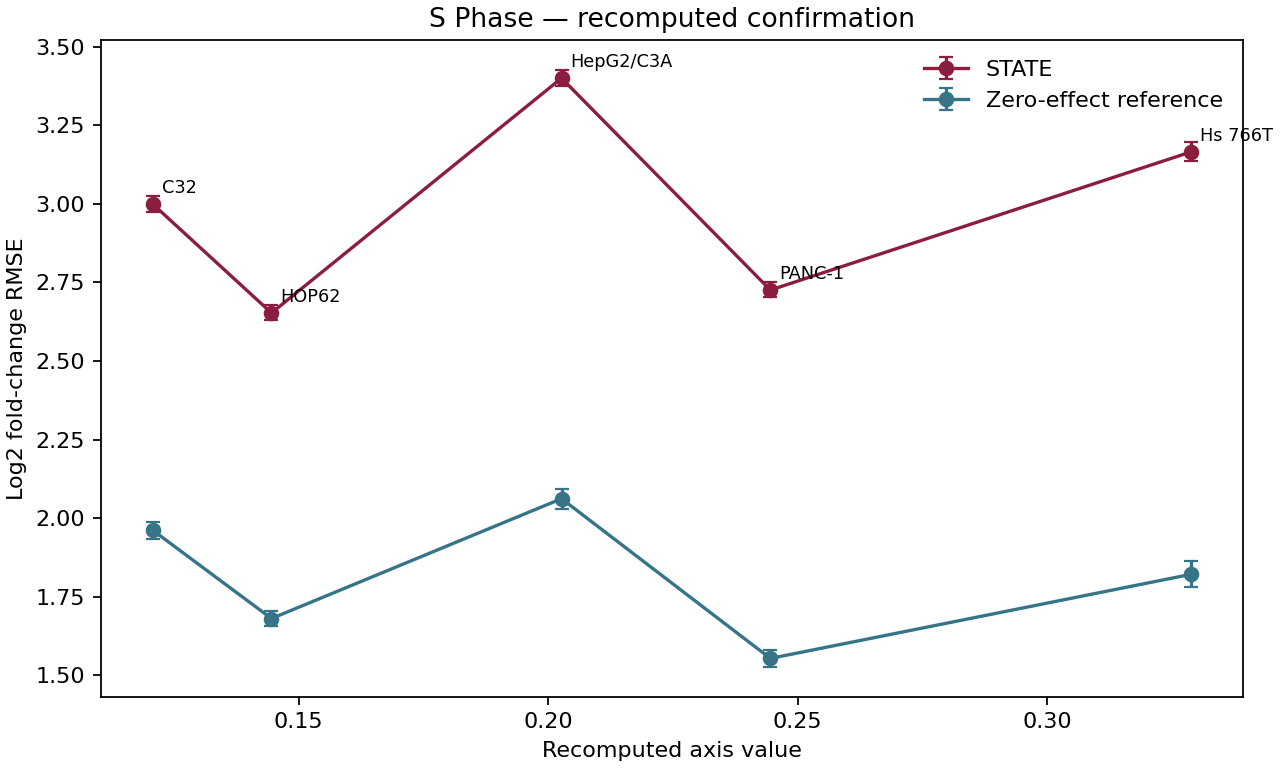

,effect_quintile,cell_count_quintile,C32,HOP62,HepG2/C3A,Hs 766T,PANC-1
0,0,2,0,0,0,0,1
1,0,3,6,24,20,19,60
2,0,4,37,171,19,149,298
3,1,1,0,0,1,0,0
4,1,2,8,27,42,42,46
5,1,3,80,160,36,102,151
6,1,4,12,47,0,15,35
7,2,0,0,0,2,0,0
8,2,1,9,21,71,40,26
9,2,2,153,130,46,88,74


Matching rows: 4020 — inspect full assignment/weights in the linked CSV.


,target,overlap_at_N,overlap_at_50,overlap_at_100,overlap_at_200,overlap_at_500,precision_at_N,precision_at_50,precision_at_100,precision_at_200,...,effect_quintile,cell_count_quintile,effect_q_1,effect_q_2,effect_q_3,effect_q_4,cells_q_1,cells_q_2,cells_q_3,cells_q_4
0,"[('(S)-Crizotinib', 0.05, 'uM')]",0.117871,0.00,0.00,0.005,0.102000,0.324197,0.00,0.00,0.005,...,3,2,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,"[('(S)-Crizotinib', 0.5, 'uM')]",0.018182,0.04,0.02,0.020,0.018182,0.144339,0.04,0.02,0.020,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
2,"[('(S)-Crizotinib', 5.0, 'uM')]",0.035336,0.02,0.02,0.025,0.035336,0.184451,0.02,0.02,0.025,...,4,1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
3,"[('5-Azacytidine', 0.05, 'uM')]",0.061453,0.02,0.02,0.030,0.061453,0.221821,0.02,0.02,0.030,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,"[('5-Azacytidine', 0.5, 'uM')]",0.098624,0.02,0.02,0.010,0.098624,0.284368,0.02,0.02,0.010,...,4,1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
5,"[('5-Azacytidine', 5.0, 'uM')]",0.088398,0.00,0.00,0.030,0.088398,0.223827,0.00,0.00,0.030,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
6,"[('5-Fluorouracil', 0.05, 'uM')]",0.034268,0.02,0.03,0.020,0.034268,0.191317,0.02,0.03,0.020,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
7,"[('5-Fluorouracil', 0.5, 'uM')]",0.062222,0.00,0.01,0.015,0.062222,0.280211,0.00,0.01,0.015,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
8,"[('5-Fluorouracil', 5.0, 'uM')]",0.084932,0.06,0.07,0.060,0.084932,0.209549,0.06,0.07,0.060,...,2,2,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
9,"[('8-Hydroxyquinoline', 0.05, 'uM')]",0.055363,0.02,0.03,0.045,0.055363,0.177598,0.02,0.03,0.045,...,2,2,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


**ST-HVG discovery analysis on the same source-built S-phase axis**

,analysis,estimate,se_cluster,p_one_sided,p_two_sided,n_rows,n_targets,n_compounds,controls,bootstrap_ci95,ci95
0,models / state_raw,0.091276,0.009873,1.180212e-20,2.360424e-20,1660.0,332.0,111.0,[],"[0.072015224871879, 0.11029507074414754]",NaN
1,models / state_adjusted,0.121746,0.007827,7.433878e-55,1.486776e-54,1660.0,332.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']","[0.10586734866314558, 0.13655950880126344]",NaN
2,models / identity_raw,-0.029770,0.010728,9.972396e-01,5.520784e-03,1660.0,332.0,111.0,[],"[-0.05078113670388633, -0.008797217810251265]",NaN
3,paired_state_minus_identity,0.121046,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.11200061808715096, 0.1301766816579059]"
4,dose_sensitivity / 0.05,0.140692,0.009612,8.057243e-49,1.611449e-48,555.0,111.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
5,dose_sensitivity / 0.5,0.127908,0.009186,2.277530e-44,4.555059e-44,550.0,110.0,110.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
6,dose_sensitivity / 5.0,0.097218,0.009839,2.509944e-23,5.019887e-23,555.0,111.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
7,leave_one_context_out / C32,0.106262,0.008035,3.168006e-40,6.336012e-40,1328.0,332.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
8,leave_one_context_out / HOP62,0.139877,0.007109,1.749988e-86,3.499976e-86,1328.0,332.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
9,leave_one_context_out / HepG2/C3A,0.096436,0.007375,2.276860e-39,4.553719e-39,1328.0,332.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN


,analysis,estimate,se_cluster,p_one_sided,p_two_sided,n_rows,n_targets,n_compounds,controls,bootstrap_ci95,ci95
0,models / state_raw,0.091276,0.009873,1.180212e-20,2.360424e-20,1660.0,332.0,111.0,[],"[0.072015224871879, 0.11029507074414754]",NaN
1,models / state_adjusted,0.121746,0.007827,7.433878e-55,1.486776e-54,1660.0,332.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']","[0.10586734866314558, 0.13655950880126344]",NaN
2,models / identity_raw,-0.029770,0.010728,9.972396e-01,5.520784e-03,1660.0,332.0,111.0,[],"[-0.05078113670388633, -0.008797217810251265]",NaN
3,paired_state_minus_identity,0.121046,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.11200061808715096, 0.1301766816579059]"
4,dose_sensitivity / 0.05,0.140692,0.009612,8.057243e-49,1.611449e-48,555.0,111.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
5,dose_sensitivity / 0.5,0.127908,0.009186,2.277530e-44,4.555059e-44,550.0,110.0,110.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
6,dose_sensitivity / 5.0,0.097218,0.009839,2.509944e-23,5.019887e-23,555.0,111.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
7,leave_one_context_out / C32,0.106262,0.008035,3.168006e-40,6.336012e-40,1328.0,332.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
8,leave_one_context_out / HOP62,0.139877,0.007109,1.749988e-86,3.499976e-86,1328.0,332.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
9,leave_one_context_out / HepG2/C3A,0.096436,0.007375,2.276860e-39,4.553719e-39,1328.0,332.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN


In [6]:
wf.source_functions(ROOT,'methods/original/04_analyze_frozen_axis.py',['within_design','fit_within','context_spc'])
wf.source_functions(ROOT,'methods/reconstruct.py',['bootstrap_slopes_fast','quintile_matching'])
analysis=wf.read_json(ROOT,f'computed/analysis/{AXIS}/analysis.json')
display(JSON(analysis['policy']))
display(pd.Series(analysis['computed_diagnostics'],name='recomputed_diagnostic').to_frame())
print('Main displayed fits: confirmation partition; discovery/all fits remain in analysis.json.')
fits=wf.show_fits(analysis['partitions']['confirmation'])
curve=wf.read_csv(ROOT,f'computed/analysis/{AXIS}/spc_table.csv')
display(curve)
wf.show_curve(ROOT,AXIS)
strata=wf.read_csv(ROOT,f'computed/analysis/{AXIS}/matching_strata.csv')
weights=wf.read_csv(ROOT,f'computed/analysis/{AXIS}/matching_weights.csv')
display(strata)
print('Matching rows:',len(weights),'— inspect full assignment/weights in the linked CSV.')
display(weights.head(10))
display(Markdown('**ST-HVG discovery analysis on the same source-built S-phase axis**'))
wf.show_fits(wf.read_json(ROOT,f'computed/analysis/{AXIS}/hvg_discovery_analysis.json'))


## 7. Historical result and decision

The historical decision separated a strong adjusted positive association from a non-monotonic five-context curve. The report recorded Spearman rho 0.30 against its frozen 0.70 threshold. Here the curve, correlation and regression evidence are recalculated; the original disposition is retained as history.

In [7]:
comparison=wf.historical_comparison(ROOT,'s_phase')
from scipy.stats import spearmanr
xcol='axis_value' if 'axis_value' in curve else 'distance'
rho=float(spearmanr(curve[xcol],curve.state_rmse_mean).statistic)
print('Recomputed five-context curve Spearman rho:',rho)
print('Original documented shape threshold: 0.70; reconstructed shape passes:',rho>=0.70)
wf.original_decision(ROOT,'baseline_s_phase_score_heterogeneity','Historical finding: strong adjusted regression with stable continuous controls, but the original context-ordering requirement failed. The analysis and curve above are the newly calculated evidence.')


,axis,metric,historical,recomputed,difference,tolerance,within_tolerance,note
8,s_phase,state_raw,0.080560,0.080561,1.424301e-06,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.
9,s_phase,state_adjusted,0.095150,0.095149,-7.615264e-07,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.
10,s_phase,identity_raw,-0.038700,-0.038704,-4.141988e-06,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.
11,s_phase,paired_state_minus_identity,0.119270,0.119266,-4.433711e-06,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.
12,s_phase,context_spearman,0.300000,0.300000,0.000000e+00,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.
13,s_phase,quintile_matching,0.104940,0.106972,2.031559e-03,NaN,NaN,Original eight quintile-control columns and full-row inclusion recovered; partition-specific cut...
14,s_phase,confirmation_rows,4020.000000,4020.000000,0.000000e+00,0.000000e+00,True,Reported rounded value; no calculation choice is changed to obtain agreement.
15,s_phase,confirmation_targets,804.000000,804.000000,0.000000e+00,0.000000e+00,True,Reported rounded value; no calculation choice is changed to obtain agreement.
16,s_phase,confirmation_compounds,268.000000,268.000000,0.000000e+00,0.000000e+00,True,Reported rounded value; no calculation choice is changed to obtain agreement.
17,s_phase,confirmation_contexts,5.000000,5.000000,0.000000e+00,0.000000e+00,True,Reported rounded value; no calculation choice is changed to obtain agreement.


Historical values are validation targets only. Differences are reported rather than used to tune inputs or calculations.


Recomputed five-context curve Spearman rho: 0.3
Original documented shape threshold: 0.70; reconstructed shape passes: False


**Original decision:** `axis_negative_strong_regression_but_shape_failed`

Historical finding: strong adjusted regression with stable continuous controls, but the original context-ordering requirement failed. The analysis and curve above are the newly calculated evidence.

Historical overall disposition: CLOSED_NEGATIVE_NO_CERTIFIED_GENERALIZABILITY_FAILURE
This records the original agent determination; it does not create a new scientific certification.
